# Notebook 2 — Loaders and Chunking

Notebook 1 used one Markdown file and one splitter setting. Real projects have PDFs, web
pages, and many files at once, and **how you split them changes what the search finds**.
This notebook looks at both steps of indexing that come before the embeddings: loading and
chunking.

**What you will learn**

1. What a loader is, and how to write one for text, PDF, and HTML files.
2. Why metadata matters.
3. How text splitters work: separators, chunk size, and overlap.
4. How chunk size changes search quality, measured on real questions.
5. How to split by headings and keep the section name.
6. How to run RAG over several documents with sources.

**Before you start**

```bash
ollama pull gpt-oss:20b
ollama pull nomic-embed-text
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 45 minutes.

## 1. Setup

In [1]:
from operator import itemgetter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import (
    CharacterTextSplitter,
    Language,
    MarkdownHeaderTextSplitter,
    RecursiveCharacterTextSplitter,
)

from roadmap import get_chat_model, get_embeddings
from roadmap.loaders import load_directory

llm = get_chat_model()
embeddings = get_embeddings()

DATA = Path("data")
ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

for file in sorted(DATA.iterdir()):
    print(f"{file.name:<14} {file.stat().st_size:>6} bytes")

handbook.md      5078 bytes
handbook.pdf     5187 bytes
it_faq.html      2699 bytes
make_pdf.py      1276 bytes


Besides the handbook from Notebook 1 (as Markdown and as PDF), there is a second document:
`it_faq.html`, a web page with questions and answers from Brightleaf's IT help desk.
(`make_pdf.py` is the script that built the PDF; it is not a document.)

## 2. What is a loader?

![A loader turns a file into Documents](assets/loaders.svg)

> **Loader:** code that reads a file and returns `Document` objects: the text, plus
> metadata such as the file name or page number.

Libraries offer ready-made loaders for hundreds of formats. (LangChain's old collection,
`langchain-community`, is no longer maintained.) For common formats, a few lines of your
own code are enough, and you decide exactly what ends up in the text. Let's write three.

### 2.1 Text and Markdown

The simplest loader: read the file, keep the file name.

In [2]:
def load_text(path: Path) -> list[Document]:
    return [Document(page_content=path.read_text(encoding="utf-8"), metadata={"source": path.name})]


[handbook_md] = load_text(DATA / "handbook.md")
print(handbook_md.metadata, "|", len(handbook_md.page_content), "characters")

{'source': 'handbook.md'} | 5078 characters


### 2.2 PDF

A PDF stores its text page by page. The `pypdf` library takes the text out. We create **one
Document per page** and store the page number, so an answer can later say "page 2".

In [3]:
from pypdf import PdfReader


def load_pdf(path: Path) -> list[Document]:
    documents = []
    for number, page in enumerate(PdfReader(path).pages, start=1):
        text = (page.extract_text() or "").strip()
        if text:  # skip empty pages
            documents.append(
                Document(page_content=text, metadata={"source": path.name, "page": number})
            )
    return documents


pdf_pages = load_pdf(DATA / "handbook.pdf")
for page in pdf_pages:
    print(page.metadata, "|", len(page.page_content), "characters")
print("\nStart of page 1:\n" + pdf_pages[0].page_content[:250])

{'source': 'handbook.pdf', 'page': 1} | 1821 characters
{'source': 'handbook.pdf', 'page': 2} | 1858 characters
{'source': 'handbook.pdf', 'page': 3} | 1309 characters

Start of page 1:
Brightleaf Employee Handbook
Brightleaf is a made-up software company. This handbook is sample data for the roadmap
notebooks. Every name, number, and rule in it is invented.
Version 3.2, valid from January 2026.
1. Working hours
Our core hours are 1


Compare this with the Markdown file: the text is the same, but the `#` heading marks are
gone, because a PDF only stores text and its position on the page. Line breaks also follow
the page layout, not the paragraphs.

> **Scanned PDFs** are images of pages and contain no text at all. `extract_text()` returns
> nothing for them; you would need OCR (optical character recognition) first.

### 2.3 HTML web pages

A web page contains much more than its content: menus, scripts, styles, and a footer. Here is
part of the raw file:

In [4]:
raw_html = (DATA / "it_faq.html").read_text(encoding="utf-8")
print(raw_html[:520])

<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <title>Brightleaf IT Help Desk FAQ</title>
  <style>body { font-family: sans-serif; max-width: 720px; margin: 2rem auto; }</style>
  <script>console.log("analytics");</script>
</head>
<body>
  <nav>Home | People | IT Help Desk | Facilities | Log out</nav>

  <main>
    <h1>IT Help Desk FAQ</h1>
    <p>Sample data for the roadmap notebooks. Brightleaf is a made-up company.</p>

    <h2>How do I reset my password?</h2>
    <p>Open the self-service por


The loader below uses **BeautifulSoup** to parse the HTML. It removes the parts that are not
content, turns headings into Markdown headings (`#`, `##`), and joins the remaining
paragraphs.

In [5]:
from bs4 import BeautifulSoup


def load_html(path: Path) -> list[Document]:
    soup = BeautifulSoup(path.read_text(encoding="utf-8"), "html.parser")
    title = soup.title.get_text(strip=True) if soup.title else path.stem
    for tag in soup(["script", "style", "nav", "header", "footer", "aside"]):
        tag.decompose()  # remove the tag and everything inside it

    blocks = []
    for element in soup.body.find_all(["h1", "h2", "h3", "p", "li"]):
        text = " ".join(element.get_text(" ").split())  # also fixes extra spaces and line breaks
        if element.name.startswith("h"):
            text = "#" * int(element.name[1]) + " " + text
        blocks.append(text)
    return [
        Document(page_content="\n\n".join(blocks), metadata={"source": path.name, "title": title})
    ]


[faq] = load_html(DATA / "it_faq.html")
print(faq.metadata)
print(faq.page_content[:420])

{'source': 'it_faq.html', 'title': 'Brightleaf IT Help Desk FAQ'}
# IT Help Desk FAQ

Sample data for the roadmap notebooks. Brightleaf is a made-up company.

## How do I reset my password?

Open the self-service portal and choose "Forgot password". You will get a code on your work phone. If you are locked out after five wrong tries, call the help desk on extension 4400.

## How do I connect to the VPN?

Install the VPN app from the company software center and sign in with your wor


The menu ("Home | People | ...") and the footer are gone, and the questions became `##`
headings. For a real website you would first download the page (for example with
`urllib.request.urlopen(url).read()`), check that the site allows it, and then parse it the
same way.

### 2.4 Load a whole folder

The three loaders above, plus `load_file()` (pick a loader by file extension) and
`load_directory()` (load every supported file in a folder), are saved in
[`src/roadmap/loaders.py`](../src/roadmap/loaders.py). From now on we import them from there.

In [6]:
documents = load_directory(DATA)

for document in documents:
    print(f"{document.metadata!s:<70} {len(document.page_content):>5} characters")

{'source': 'handbook.md'}                                               5078 characters
{'source': 'handbook.pdf', 'page': 1}                                   1821 characters
{'source': 'handbook.pdf', 'page': 2}                                   1858 characters
{'source': 'handbook.pdf', 'page': 3}                                   1309 characters
{'source': 'it_faq.html', 'title': 'Brightleaf IT Help Desk FAQ'}       1991 characters


`make_pdf.py` was skipped because `.py` is not a supported document type.

## 3. Why metadata matters

Metadata is copied into every chunk that is cut from a document. That is how a RAG app can:

- **cite its sources**: "handbook.pdf, page 1",
- **filter the search**: only search the IT FAQ, or only documents from 2026 (Stage 3),
- **find duplicates**: the Markdown and PDF handbooks hold the same text.

The last point matters here. If we indexed both handbook files, every fact would exist twice
and the duplicates would take two of the top-k places. So for the rest of this notebook we
use the Markdown handbook and the IT FAQ:

In [7]:
sources = [doc for doc in documents if doc.metadata["source"] in ("handbook.md", "it_faq.html")]
print([doc.metadata["source"] for doc in sources])

['handbook.md', 'it_faq.html']


## 4. How text splitters work

> **Text splitter:** cuts a document into chunks of at most `chunk_size` characters.

![The recursive splitter](assets/recursive_splitter.svg)

### 4.1 One separator vs. several

`CharacterTextSplitter` cuts at **one** separator, for example blank lines (paragraphs).
`RecursiveCharacterTextSplitter` tries a list of separators: paragraphs first, then lines,
then words, then single characters, until every piece fits.

Let's split the "Company vehicles" section with a small `chunk_size` of 150 characters. Its
second paragraph is longer than that:

In [8]:
text = handbook_md.page_content
vehicles = text[text.index("## 7.") : text.index("## 8.")].strip()

splitters = {
    "CharacterTextSplitter": CharacterTextSplitter(
        separator="\n\n", chunk_size=150, chunk_overlap=0
    ),
    "RecursiveCharacterTextSplitter": RecursiveCharacterTextSplitter(
        chunk_size=150, chunk_overlap=0
    ),
}
for name, splitter in splitters.items():
    print(f"=== {name}")
    for chunk in splitter.split_text(vehicles):
        flag = "  <- too long!" if len(chunk) > 150 else ""
        print(f"{len(chunk):>4} characters{flag}")
    print()

Created a chunk of size 183, which is longer than the specified 150


=== CharacterTextSplitter
 117 characters
 183 characters  <- too long!
 111 characters

=== RecursiveCharacterTextSplitter
 117 characters
  92 characters
  90 characters
 111 characters



`CharacterTextSplitter` cannot cut inside a paragraph, so the long paragraph stays too long
(it also prints a warning). The recursive splitter falls back to line breaks and keeps every
chunk within the limit. **Use `RecursiveCharacterTextSplitter` as your default.**

### 4.2 Chunk overlap

![Chunk overlap](assets/chunk_overlap.svg)

> **Chunk overlap:** how many characters at the end of one chunk are repeated at the start of
> the next one.

When a cut falls in the middle of a sentence, neither chunk holds the whole sentence. Overlap
repeats a little text, so the sentence is complete in at least one chunk. To see it clearly,
we split the "Vacation" section on spaces only:

In [9]:
vacation = text[text.index("## 3.") : text.index("## 4.")].strip()

for overlap in (0, 40):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=150, chunk_overlap=overlap, separators=[" "]
    )
    print(f"=== chunk_overlap={overlap}")
    for chunk in splitter.split_text(vacation)[:2]:
        print(f"[{chunk}]\n")

=== chunk_overlap=0
[## 3. Vacation

Full-time employees get 28 vacation days per calendar year. Part-time employees get vacation
days in proportion to their working]

[days.

Request vacation in the HR portal at least two weeks in advance for trips of three days or
more. Shorter breaks can be requested one day]

=== chunk_overlap=40
[## 3. Vacation

Full-time employees get 28 vacation days per calendar year. Part-time employees get vacation
days in proportion to their working]

[in proportion to their working days.

Request vacation in the HR portal at least two weeks in advance for trips of three days or
more. Shorter breaks]



With no overlap, the sentence about part-time employees ends in the first chunk ("...their
working") and continues in the second ("days."). With 40 characters of overlap, the second
chunk starts earlier and contains the whole sentence. The price: overlapping text is stored
and embedded twice. A common start is an overlap of about **10% of the chunk size**.

## 5. How chunk size changes search quality

How big should a chunk be? Instead of guessing, let's **measure**. We wrote 19 questions
whose answers we know, and for each question a short piece of text that must be in the
retrieved chunk:

In [10]:
TEST_SET = {
    "Can I eat in company vehicles?": "Eating and drinking in company vehicles",
    "How many vacation days do I get?": "28 vacation days",
    "How much is the learning budget?": "learning budget of 1,200",
    "When do I need a doctor's note?": "doctor's note is required",
    "How much can a hotel cost per night?": "Hotels may cost up to 150 EUR",
    "Can I work from another country?": "Working from another country is allowed",
    "Who pays a parking fine?": "Parking fines",
    "How much of my phone costs are covered?": "Phone costs are covered up to 40 EUR",
    "How long is paid parental leave?": "16 weeks of paid parental leave",
    "Is there money for my home internet?": "home office allowance of 30 EUR",
    "What happens to unused vacation days?": "Up to five unused vacation days",
    "What should I do in case of fire?": "In case of fire",
    "How do I reset my password?": "Forgot password",
    "Do I need the VPN for email?": "It is not needed for email or chat",
    "What is the Wi-Fi password for visitors?": "Brightleaf-Guest",
    "How many color pages can I print?": "Color printing is limited to 50 pages",
    "Are files on my laptop backed up?": "Files saved only on your laptop are not backed up",
    "I clicked a link in a phishing email. What now?": "If you already clicked a link",
    "How often are laptops replaced?": "Laptops are replaced every four years",
}

question_vectors = np.array([embeddings.embed_query(q) for q in TEST_SET])
question_vectors /= np.linalg.norm(question_vectors, axis=1, keepdims=True)
print(len(TEST_SET), "test questions embedded")

19 test questions embedded


For every setting we measure two things:

> **Hit rate (hit@1):** the share of questions where the **first** retrieved chunk contains
> the answer.
>
> **Characters sent:** how much text the top 3 chunks put into the prompt. More text means
> slower and more expensive answers.

In [11]:
def evaluate(chunks: list[Document], k: int = 3) -> dict:
    chunk_vectors = np.array(embeddings.embed_documents([c.page_content for c in chunks]))
    chunk_vectors /= np.linalg.norm(chunk_vectors, axis=1, keepdims=True)
    hits, characters = 0, []
    for question_vector, needle in zip(question_vectors, TEST_SET.values(), strict=True):
        top = np.argsort(-(chunk_vectors @ question_vector))[:k]
        hits += needle in chunks[top[0]].page_content
        characters.append(sum(len(chunks[i].page_content) for i in top))
    return {"chunks": len(chunks), "hit@1": hits / len(TEST_SET), "chars": np.mean(characters)}


sizes = [100, 200, 300, 500, 800, 1200, 2000]
results = []
for size in sizes:
    splitter = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=size // 10)
    results.append(evaluate(splitter.split_documents(sources)))
    r = results[-1]
    print(
        f"chunk_size {size:>4}: {r['chunks']:>3} chunks  hit@1 {r['hit@1']:>4.0%}  "
        f"chars sent {r['chars']:>5.0f}"
    )

chunk_size  100: 106 chunks  hit@1  68%  chars sent   210


chunk_size  200:  52 chunks  hit@1  79%  chars sent   442


chunk_size  300:  33 chunks  hit@1  84%  chars sent   690
chunk_size  500:  19 chunks  hit@1  95%  chars sent  1185


chunk_size  800:  10 chunks  hit@1  95%  chars sent  2211
chunk_size 1200:   7 chunks  hit@1  89%  chars sent  3181
chunk_size 2000:   4 chunks  hit@1  63%  chars sent  5382


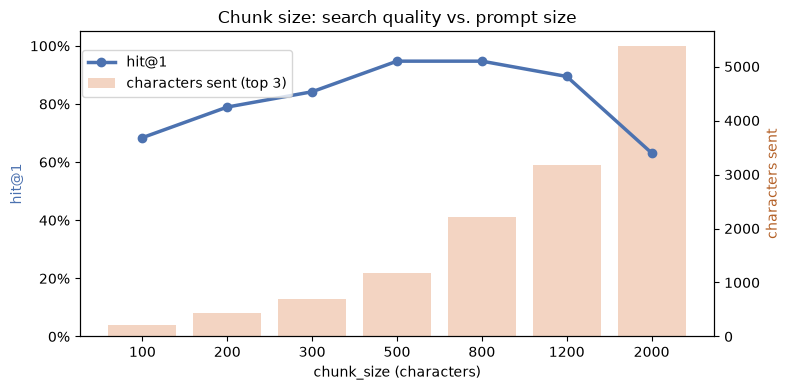

In [12]:
fig, ax_hits = plt.subplots(figsize=(8, 4))
ax_chars = ax_hits.twinx()
positions = range(len(sizes))

ax_chars.bar(
    positions,
    [r["chars"] for r in results],
    color="#DD8452",
    alpha=0.35,
    label="characters sent (top 3)",
)
ax_hits.plot(
    positions,
    [r["hit@1"] for r in results],
    marker="o",
    color="#4C72B0",
    linewidth=2.5,
    label="hit@1",
)
ax_hits.set_zorder(ax_chars.get_zorder() + 1)
ax_hits.patch.set_visible(False)

ax_hits.set_xticks(positions, sizes)
ax_hits.set_xlabel("chunk_size (characters)")
ax_hits.set_ylabel("hit@1", color="#4C72B0")
ax_hits.set_ylim(0, 1.05)
ax_hits.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax_chars.set_ylabel("characters sent", color="#B35F25")
ax_hits.set_title("Chunk size: search quality vs. prompt size")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
fig.tight_layout()
fig.savefig(ASSETS / "chunk_size_tradeoff.png", dpi=120)
plt.show()

**What to notice**

- **Tiny chunks (100 characters)** are often half a sentence. They lose their meaning, so the
  right chunk is first for only about two thirds of the questions.
- **Huge chunks (2,000 characters)** mix many topics. The one sentence that matters is buried,
  so the right chunk stops standing out, and every answer sends about 25 times more text
  than with the tiny chunks.
- In between (about **500 to 800 characters**) the search works best for our documents.

These numbers come from 19 questions on two small documents, so treat them as a direction,
not a law. For your own documents, **build a small test set and measure**. A good starting
point is a chunk size of about 500 characters with 10% overlap.

## 6. Split by headings

Our documents have headings, and a heading is a natural place to cut. There are two ways to
use them:

1. **Markdown-aware recursive splitting** (Notebook 1): add the heading levels to the list of
   separators, so cuts happen at headings first.
2. **`MarkdownHeaderTextSplitter`**: cut at headings and copy the heading text into the
   chunk's **metadata**. Long sections are then split again with the recursive splitter.

In [13]:
header_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[("#", "title"), ("##", "section")], strip_headers=False
)
size_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)


def split_by_headings(docs: list[Document]) -> list[Document]:
    chunks = []
    for doc in docs:
        for part in header_splitter.split_text(doc.page_content):
            part.metadata = {**doc.metadata, **part.metadata}  # keep "source" too
            chunks.extend(size_splitter.split_documents([part]))
    return chunks


heading_chunks = split_by_headings(sources)
for chunk in heading_chunks[2:5]:
    print(chunk.metadata)
    print("   ", chunk.page_content[:70].replace("\n", " "), "...\n")

{'source': 'handbook.md', 'title': 'Brightleaf Employee Handbook', 'section': '2. Remote work'}
    ## 2. Remote work   You can work from home up to three days per week.  ...

{'source': 'handbook.md', 'title': 'Brightleaf Employee Handbook', 'section': '2. Remote work'}
    employees also receive a one-time budget of 400 EUR for a desk chair a ...

{'source': 'handbook.md', 'title': 'Brightleaf Employee Handbook', 'section': '3. Vacation'}
    ## 3. Vacation   Full-time employees get 28 vacation days per calendar ...



Look at the second chunk: it is the second half of "2. Remote work". Its text has no heading,
but its metadata still says which section it belongs to. That makes much better sources.

Now let's compare the three strategies at the same chunk size:

In [14]:
strategies = {
    "plain recursive": RecursiveCharacterTextSplitter(
        chunk_size=500, chunk_overlap=50
    ).split_documents(sources),
    "markdown-aware recursive": RecursiveCharacterTextSplitter.from_language(
        Language.MARKDOWN, chunk_size=500, chunk_overlap=50
    ).split_documents(sources),
    "headings + metadata": heading_chunks,
}

print(f"{'strategy':<26} {'chunks':>6} {'hit@1':>6} {'chars sent':>11}")
for name, chunks in strategies.items():
    r = evaluate(chunks)
    print(f"{name:<26} {r['chunks']:>6} {r['hit@1']:>6.0%} {r['chars']:>11.0f}")

strategy                   chunks  hit@1  chars sent
plain recursive                19    95%        1185


markdown-aware recursive       21   100%         986


headings + metadata            24   100%         904


Cutting at headings helps: both heading-based strategies put the right chunk first for every
question, and they send less text, because chunks no longer mix the end of one section with
the start of the next. `MarkdownHeaderTextSplitter` adds section names to the metadata on
top.

This only works when the text still **has** headings. Our HTML loader kept them (as `#`),
but the PDF loader could not. For PDFs, the plain recursive splitter is the usual choice.

## 7. RAG over several documents

Let's put it together: both documents, split by headings, in one vector store. The sources
now show the file **and** the section.

In [15]:
vector_store = InMemoryVectorStore.from_documents(heading_chunks, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 3})


def format_docs(docs: list[Document]) -> str:
    return "\n\n---\n\n".join(doc.page_content for doc in docs)


def cite(doc: Document) -> str:
    section = doc.metadata.get("section") or doc.metadata.get("title", "")
    return f"{doc.metadata['source']} > {section}"


def make_rag_chain(system_prompt: str):
    prompt = ChatPromptTemplate.from_messages([("system", system_prompt), ("user", "{question}")])
    return (
        RunnablePassthrough.assign(docs=itemgetter("question") | retriever)
        | RunnablePassthrough.assign(context=lambda x: format_docs(x["docs"]))
        | RunnablePassthrough.assign(answer=prompt | llm | StrOutputParser())
    )


def ask(chain, questions: list[str]) -> None:
    for question in questions:
        result = chain.invoke({"question": question})
        print(f"Q: {question}\nA: {result['answer']}")
        print("   sources:", " | ".join(cite(doc) for doc in result["docs"]), "\n")


STRICT_PROMPT = (
    "You answer questions from Brightleaf employees. Use only the context below. If the "
    "answer is not in the context, say: I don't know.\n\nContext:\n{context}"
)
QUESTIONS = [
    "Can I drink coffee in the company car?",
    "My laptop broke. Can I get another one today?",
    "How many vacation days can I take into next year?",
]

ask(make_rag_chain(STRICT_PROMPT), QUESTIONS)

Q: Can I drink coffee in the company car?
A: I don’t know.
   sources: handbook.md > 7. Company vehicles | handbook.md > 9. Mobile phone policy | it_faq.html > How do I connect to the VPN? 



Q: My laptop broke. Can I get another one today?
A: Yes—if you report the issue to the IT help desk, they can loan you a replacement laptop on the same day while your own is being repaired.
   sources: it_faq.html > My laptop is slow or broken. What now? | it_faq.html > Are my files backed up? | handbook.md > 8. Equipment and IT security 



Q: How many vacation days can I take into next year?
A: You can carry over **up to five unused vacation days** into the next calendar year.
   sources: handbook.md > 3. Vacation | handbook.md > 4. Sick leave | handbook.md > 2. Remote work 



The second and third answers are right. But look at the coffee question: the right section
was retrieved first, and it says "Eating and drinking in company vehicles is not allowed,
except for water". Still the model says "I don't know".

The problem is not the search, it is the **prompt**. The handbook never mentions coffee. To
answer, the model has to take one small step: coffee is a drink, and it is not water. With
the strict rule "if the answer is not in the context, say I don't know", the model decides
that the exact answer is not written there. Grounding that is too strict makes the model refuse answers it
could give.

The fix is to say more clearly what counts as "in the context":

In [16]:
CLEAR_PROMPT = (
    "You answer questions from Brightleaf employees, using only the context below. The "
    "answer may be a yes or a no, or may need a small step of reasoning from the context. "
    "Only if the context does not cover the question, say: I don't know."
    "\n\nContext:\n{context}"
)

ask(make_rag_chain(CLEAR_PROMPT), [*QUESTIONS, "Can I bring my dog to the office?"])

Q: Can I drink coffee in the company car?
A: No, coffee is not allowed in the company car. Only water is permitted.
   sources: handbook.md > 7. Company vehicles | handbook.md > 9. Mobile phone policy | it_faq.html > How do I connect to the VPN? 



Q: My laptop broke. Can I get another one today?
A: Yes – the help desk can give you a loan laptop on the same day while yours is repaired.
   sources: it_faq.html > My laptop is slow or broken. What now? | it_faq.html > Are my files backed up? | handbook.md > 8. Equipment and IT security 



Q: How many vacation days can I take into next year?
A: You can carry over up to **five** unused vacation days into the next year.
   sources: handbook.md > 3. Vacation | handbook.md > 4. Sick leave | handbook.md > 2. Remote work 



Q: Can I bring my dog to the office?
A: I don't know.
   sources: handbook.md > 12. Health and safety | handbook.md > 9. Mobile phone policy | it_faq.html > How do I connect to the VPN? 



Now the coffee question gets a correct "no", and the model still says "I don't know" when
the documents really have no answer (there is nothing about dogs). Giving the model more
thinking time (`get_chat_model(think="medium")`) also fixes it, but it makes every answer
slower.

> **Your answers may differ.** A new model or Ollama version can change single answers: with
> an earlier version, the strict prompt also refused "Do I need the VPN to read my email from
> home?". The pattern stays the same: the stricter the rule, the more correct answers get
> refused.

**Lesson:** when a RAG answer is wrong, check both halves. Look at the retrieved chunks
(search problem, Notebook 1) **and** at the prompt (generation problem, this example).

## 8. Summary

| Topic | Key point | In code |
|---|---|---|
| Loader | A few lines that turn a file into Documents | `load_text`, `load_pdf`, `load_html` in `roadmap.loaders` |
| PDF | One Document per page; headings are lost; scans need OCR | `pypdf.PdfReader` |
| HTML | Remove menus, scripts, and footers; keep headings | `BeautifulSoup` |
| Metadata | Copied into every chunk: sources, filters, duplicates | `Document.metadata` |
| Splitter | Recursive is the safe default | `RecursiveCharacterTextSplitter` |
| Overlap | Keeps cut sentences complete; about 10% of chunk size | `chunk_overlap=50` |
| Chunk size | Too small loses meaning, too big buries facts; measure it | a small test set + hit@1 |
| Headings | Cut at headings and keep the section name | `MarkdownHeaderTextSplitter` |
| Grounding prompt | Too strict refuses answers that are there; say what counts | "may be a yes or a no, or need a small step of reasoning" |

➡️ **Next:** [Notebook 3 — Conversational RAG](03_conversational_rag.ipynb)